![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Lab | EDA Bivariate Analysis

*Diving into Amazon UK Product Insights Part II*

---

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

> **Dataset:** "UK Optimal Product Price Prediction" by asaniczka, on Kaggle
> https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/

---
## 0. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm
from scipy.stats import chi2_contingency, pearsonr, spearmanr
from scipy.stats.contingency import association

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
pd.set_option('display.max_columns', None)

---
## 1. Load the data

In [2]:
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df = data.copy()
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


---
## 2. First look

Shape, column types and missing values first:

In [3]:
df.shape

(2443651, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

There are no missing values at all. Next, the summary statistics for the numerical columns:

In [6]:
round(df.describe().T, 2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


Two things stand out here:
- **price** is extremely skewed to the right. The median is £19.09, but the mean is ~£89 and the max is **£100,000**. There are outliers to deal with in Part 2.
- **stars** has a median of 0. A rating of 0 isn't possible on Amazon, so these products probably have no rating yet. Let's check how many there are:

In [7]:
(df['stars'] == 0).mean()

np.float64(0.5015613931776673)

Apparently **~50%** of all products are unrated. Keep this in mind for the rating analysis later, because it will drag down any statistic based on `stars`.

---
## 3. Part 1 | Best-seller trends across product categories

Is the best-seller status related to the product category?

### 3.1 Crosstab

In [8]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


The raw counts are hard to compare because category sizes differ so much. Calculating the share of best-sellers for each category and sorting it in descending order:

In [9]:
crosstab_result['bestseller_share'] = crosstab_result[True] / crosstab_result.sum(axis=1)
crosstab_result.sort_values('bestseller_share', ascending=False).head(15)

isBestSeller,False,True,bestseller_share
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


How does this compare to the overall best-seller rate?

In [10]:
df['isBestSeller'].mean()

np.float64(0.003265605440384081)

Only **~0.33%** of all products are best-sellers, so the badge is rare. On the other hand, **Grocery**, **Smart Home Security & Lighting** and **Health & Personal Care** all have a share of **~5.8%**, roughly 18x the average, followed by Mobile Phone Accessories (4.2%) and Power & Hand Tools (3.5%).

Grocery and Health & Personal Care are the interesting ones: they don't just have a high share but also a large volume (~550 best-sellers each). Both are consumable, repeat-purchase categories, so it seems that customers converge on a few trusted products there. Many other categories have no best-sellers at all.

### 3.2 Statistical tests

The crosstab suggests that there is a relationship. Is it real or just chance? Running a Chi-square test with the null hypothesis:

> **H₀**: best-seller status is independent of the product category.

In [11]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])  # rebuild without the share column

chi2_stat, chi2_pvalue, dof, expected = chi2_contingency(crosstab_result)
chi2_stat, chi2_pvalue, dof

(np.float64(36540.20270061387), np.float64(0.0), 295)

In [12]:
float(chi2_pvalue) < 0.05

True

The p-value is essentially 0, so we **reject H₀**. Best-seller status and category are not independent.

But with 2.4M rows almost any difference will be significant. How strong is the association? Computing Cramér's V:

In [13]:
association(crosstab_result, method='cramer')

0.1222829439760564

Cramér's V is **~0.12**. Following Cohen's conventions (0.10–0.20 = weak), this is a **weak** association. So the category does matter, but it only explains a small part of whether a product becomes a best-seller. Product-level factors (price, reviews, brand…) probably matter more.

### 3.3 Visualizations

A stacked bar chart for the 15 categories with the highest best-seller share. It is normalised by row so that the categories are comparable:

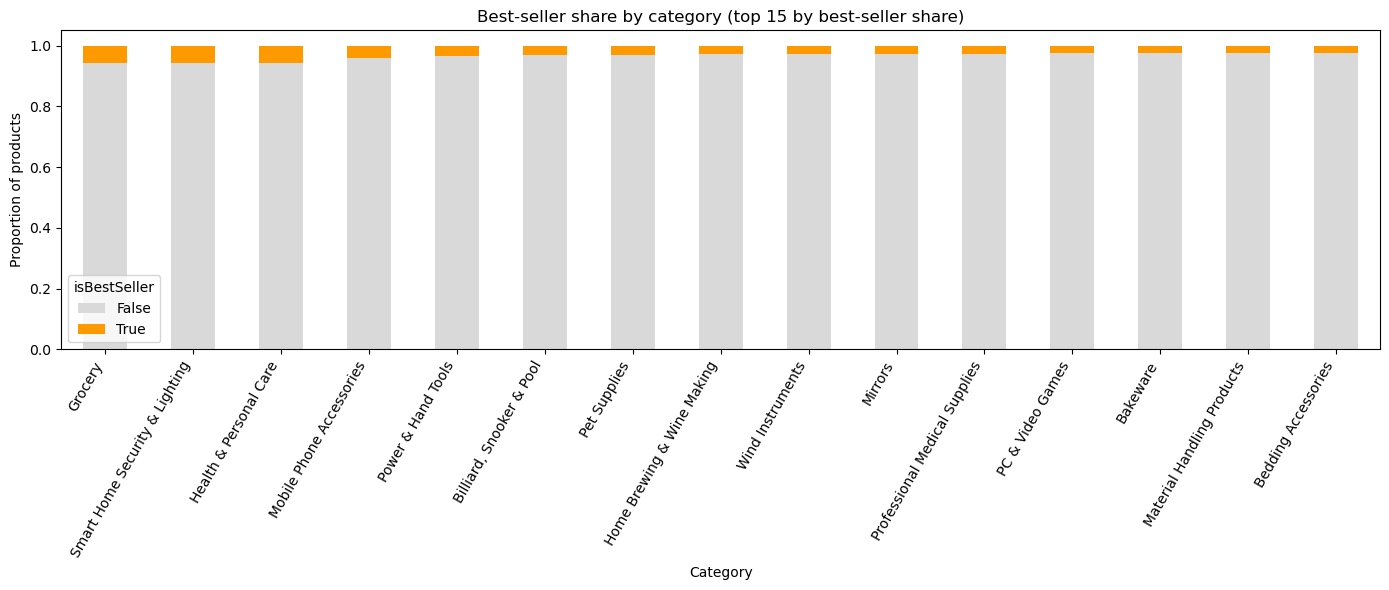

In [14]:
share = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
top_share = share.sort_values(True, ascending=False).head(15)

top_share.plot(kind='bar', stacked=True, figsize=(14, 6), color=['#d9d9d9', '#ff9900'])
plt.title('Best-seller share by category (top 15 by best-seller share)')
plt.ylabel('Proportion of products')
plt.xlabel('Category')
plt.legend(title='isBestSeller')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

And the same in absolute counts for the 15 categories with the most best-sellers:

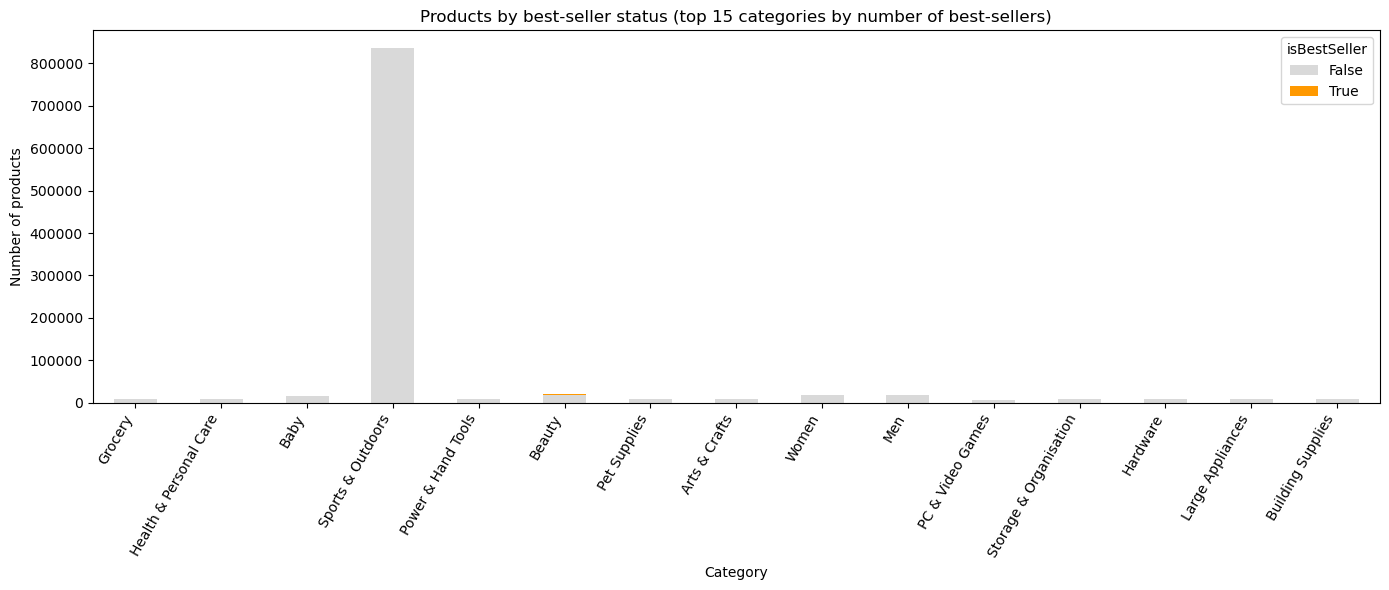

In [15]:
top_count = crosstab_result.sort_values(True, ascending=False).head(15)

top_count.plot(kind='bar', stacked=True, figsize=(14, 6), color=['#d9d9d9', '#ff9900'])
plt.title('Products by best-seller status (top 15 categories by number of best-sellers)')
plt.ylabel('Number of products')
plt.xlabel('Category')
plt.legend(title='isBestSeller')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

Even in the "best" categories the best-sellers are just a thin orange sliver: more than 94% of the products are not best-sellers. In absolute numbers, Grocery, Health & Personal Care, Baby, Sports & Outdoors and Power & Hand Tools lead. Sports & Outdoors only gets there through sheer volume though (~694k listings), and its share is very low.

---
## 4. Part 2 | Prices and ratings across categories

How do product categories influence prices?

### 4.0 Removing price outliers

As seen in section 2, price has some extreme outliers. Removing them with Tukey's method (IQR), reusing the `outlier_slayer` function from the lesson, adjusted to return the bounds:

In [16]:
def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return lower_bound, upper_bound

lower_bound, upper_bound = outlier_slayer(df['price'])
lower_bound, upper_bound

(np.float64(-44.01), np.float64(99.99000000000001))

In [17]:
df_no_out = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Removed outliers: {len(df) - len(df_no_out):,} ({(len(df) - len(df_no_out)) / len(df):.1%})")
print(f"Remaining rows:   {len(df_no_out):,}")

Removed outliers: 327,688 (13.4%)
Remaining rows:   2,115,963


With Q1 = £9.99 and Q3 = £45.99 the IQR is £36, so everything above **~£99.99** counts as an outlier. The lower bound is negative, so no cheap products get removed. That drops **~328k products (13.4%)**, which is quite a lot. Is that too aggressive? We'll find out in the bonus section. From here on everything uses `df_no_out`.

### 4.1 Violin plots

Price distribution for the 20 largest categories:

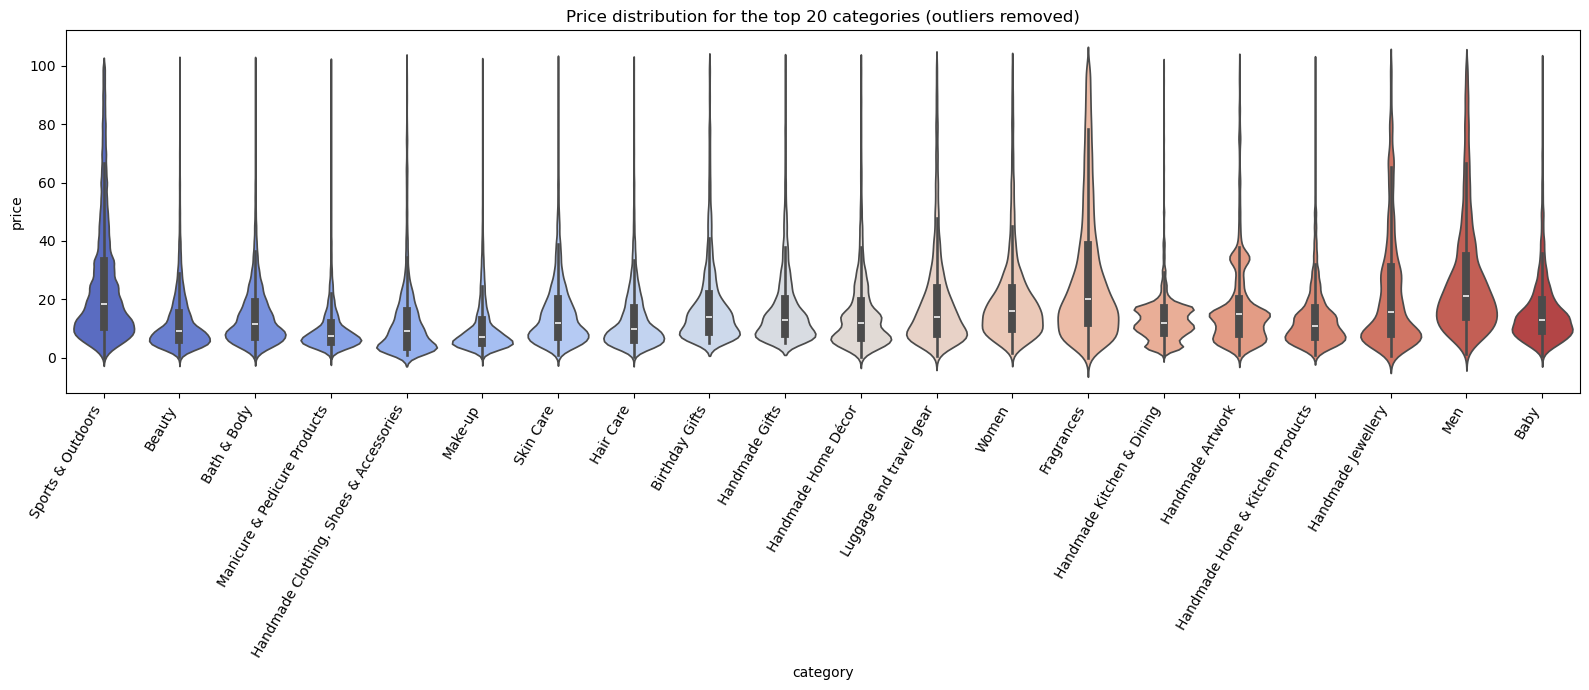

In [18]:
top20 = df_no_out['category'].value_counts().head(20).index
df_top20 = df_no_out[df_no_out['category'].isin(top20)]

plt.figure(figsize=(16, 7))
sns.violinplot(data=df_top20, x='category', y='price', order=top20, palette='coolwarm')
plt.title('Price distribution for the top 20 categories (outliers removed)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

Most of the violins are bottom-heavy: lots of products under £20, then a long thin neck up to the £100 cap. Sports & Outdoors and Luggage spread wider into higher prices, while Beauty, Make-up, Skin Care and Hair Care are concentrated at low price points.

Which category has the highest median price across *all* categories?

In [19]:
df_no_out.groupby('category')['price'].median().sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

**Desktop PCs** (£74.00), followed by Boxing Shoes, Tablets, Graphics Cards and Motherboards. These are mostly electronics and computing, and none of them are in the top 20 by volume.

### 4.2 Bar charts

Average price for the 10 largest categories:

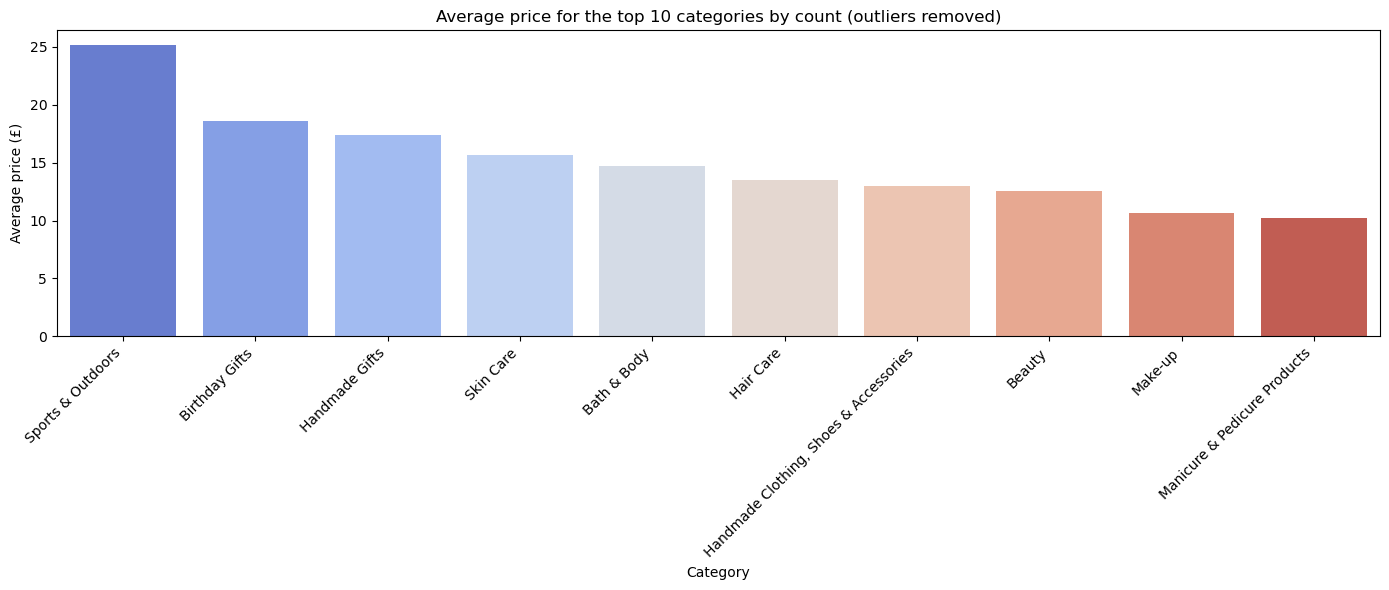

In [20]:
top10 = df_no_out['category'].value_counts().head(10).index
df_top10 = df_no_out[df_no_out['category'].isin(top10)]

avg_price_top10 = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values, palette='coolwarm')
plt.title('Average price for the top 10 categories by count (outliers removed)')
plt.ylabel('Average price (£)')
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Sports & Outdoors is the most expensive of the large categories at ~£25, while Make-up and Manicure & Pedicure Products only average ~£10–11. So the high-volume categories are dominated by low-ticket items.

Which category has the highest average price across *all* categories?

In [21]:
df_no_out.groupby('category')['price'].mean().sort_values(ascending=False).head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

**Motherboards** (~£68.77), closely followed by Boxing Shoes, Desktop PCs, Tablets and Graphics Cards. It's the same group as for the median, just in a slightly different order.

### 4.3 Box plots

Rating distribution for the 10 largest categories:

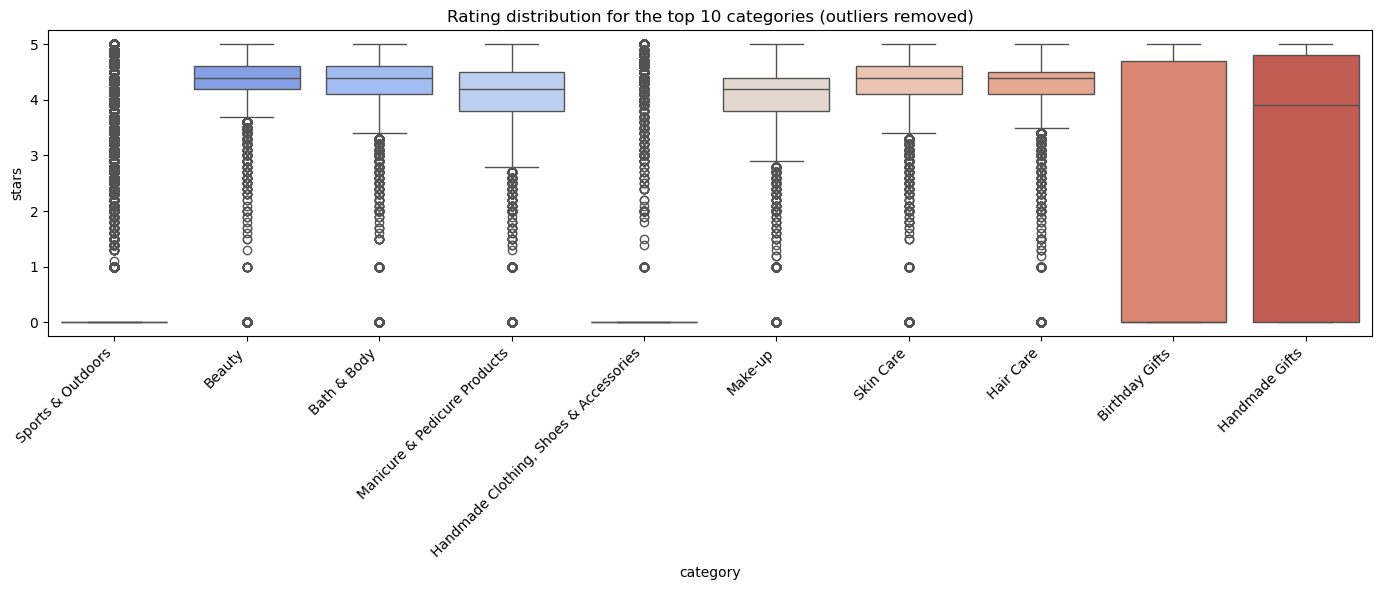

In [22]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top10, x='category', y='stars', order=top10, palette='coolwarm')
plt.title('Rating distribution for the top 10 categories (outliers removed)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Here the unrated products from section 2 show up again. The beauty categories (Bath & Body, Beauty, Hair Care, Skin Care) have medians around 4.4, while Sports & Outdoors, Birthday Gifts and Handmade Clothing have a median of **0** because most of their products are unrated. So these boxes say more about *how many reviews* a category gets than about customer satisfaction.

Which category has the highest median rating across *all* categories?

In [23]:
df_no_out.groupby('category')['stars'].median().sort_values(ascending=False).head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

**Computer Memory** (4.7), followed by a bunch of categories at 4.6 (Building & Construction Toys, Office Paper Products, Luxury Food & Drink, Kids' Play Figures…).

---
## 5. Part 3 | Price vs rating

Do more expensive products get better (or worse) ratings?

### 5.1 Correlation coefficients

In [24]:
pearson = df_no_out['price'].corr(df_no_out['stars'], method='pearson')
spearman = df_no_out['price'].corr(df_no_out['stars'], method='spearman')
round(pearson, 3), round(spearman, 3)

(np.float64(-0.078), np.float64(-0.067))

Pearson **~-0.08** and Spearman **~-0.07**: a very weak negative correlation. Is it significant?

In [25]:
pearsonr(df_no_out['price'], df_no_out['stars'])

PearsonRResult(statistic=np.float64(-0.0776729987818139), pvalue=np.float64(0.0))

The p-value is ~0, so it is *statistically* significant. With 2.1M rows that doesn't say much though. Since half of the products are unrated, they might be what's causing the effect. Checking the correlation on rated products only:

In [26]:
rated = df_no_out[df_no_out['stars'] > 0]
round(rated['price'].corr(rated['stars'], method='pearson'), 3), round(rated['price'].corr(rated['stars'], method='spearman'), 3)

(np.float64(0.007), np.float64(0.025))

Indeed, among rated products the correlation drops to **~0**. The small negative effect comes from the unrated products, which tend to be slightly more expensive (fewer people buy, and therefore review, pricier products). Conclusion: **price does not predict the rating**.

### 5.2 Visualizations

Scatter plot of price vs rating. I'm using a random sample of 100k points to keep the plot fast and readable:

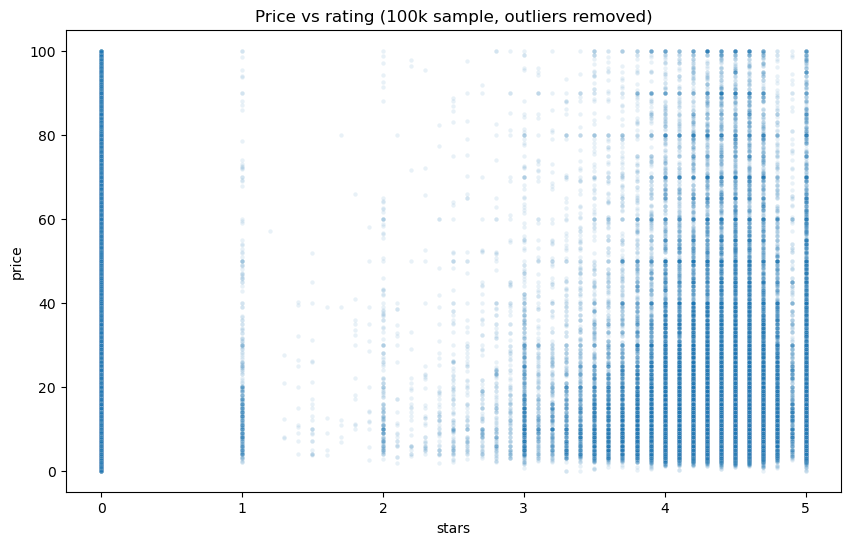

In [27]:
sample = df_no_out.sample(100_000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x='stars', y='price', alpha=0.1, s=10)
plt.title('Price vs rating (100k sample, outliers removed)')
plt.show()

The ratings are discrete (steps of 0.1) and pile up at 0 (unrated) and between 4.0 and 5.0. Every rating level covers the whole £0–£100 range, so there is no visible trend, which supports the near-zero correlation. Low ratings (1–3 stars) are rare: most rated products on Amazon UK score 4+.

Next: a correlation heatmap for all numerical variables:

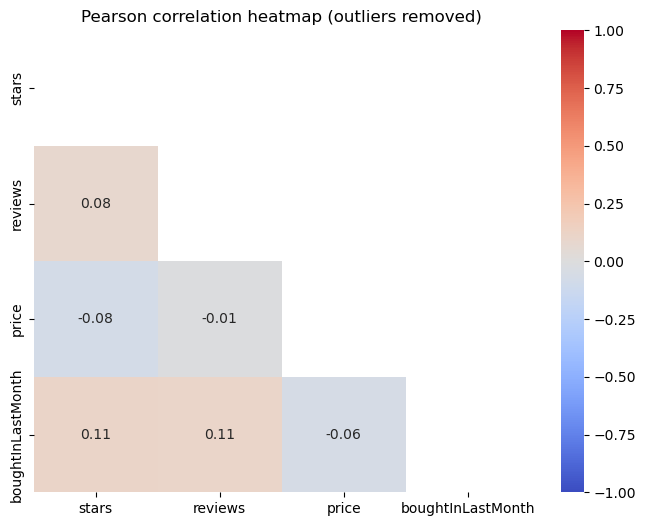

In [28]:
num = df_no_out.select_dtypes(include='number').drop(columns=['uid'])
correlation_matrix = num.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation heatmap (outliers removed)')
plt.show()

With Pearson every pair is weak (|r| < 0.12). But `reviews` and `boughtInLastMonth` are heavily skewed too, so Pearson might miss something. Trying Spearman:

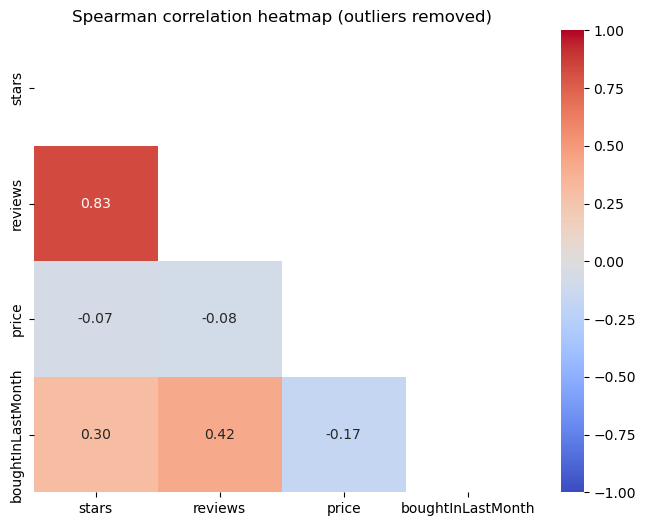

In [29]:
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(method='spearman'), mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman correlation heatmap (outliers removed)')
plt.show()

That looks different:
- `stars` and `reviews` are strongly related (**~0.83**). This is mostly because products with 0 reviews also have 0 stars.
- `reviews` and `boughtInLastMonth` are moderately related (**~0.42**): products that sell more collect more reviews.
- `price` is weakly *negatively* related to everything, especially `boughtInLastMonth` (**~-0.17**): cheaper products sell more units.

Last but not least: are prices normally distributed? Checking with a QQ plot:

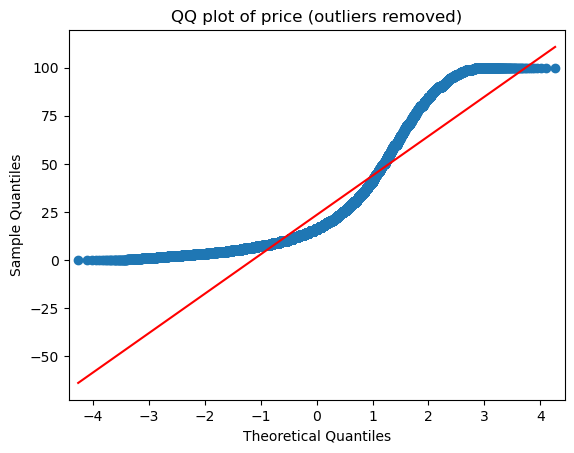

In [30]:
sm.qqplot(sample['price'], line='s')
plt.title('QQ plot of price (outliers removed)')
plt.show()

The points form a curve instead of following the red line. The lower tail sits above the line (prices can't go below £0) and the upper tail bends away. This is the typical shape of a **right-skewed** distribution. So prices are **not normally distributed**, even after removing the outliers (skewness ~1.6). Medians and Spearman are therefore the safer choice here.

---
## 6. Bonus | Same analysis without removing outliers

How much did the outlier removal change the picture? Rerunning the main steps on the full `df`:

In [31]:
df.groupby('category')['price'].median().sort_values(ascending=False).head(10)

category
Laptops                                1042.725
Desktop PCs                             810.400
Snowboards                              366.725
Home Audio Record Players               326.080
3D Printers                             319.000
Motorbike Exhaust & Exhaust Systems     313.830
Graphics Cards                          259.980
Snowboard Boots                         258.990
Lenses                                  249.990
Barebone PCs                            244.990
Name: price, dtype: float64

In [32]:
df.groupby('category')['price'].mean().sort_values(ascending=False).head(10)

category
Laptops                       1087.987827
3D Printers                   1018.036129
Desktop PCs                    926.816064
Home Office Furniture          622.135898
Test & Measurement             559.382973
Home Audio Record Players      529.665585
CPUs                           514.519317
Digital Cameras                496.156185
Material Handling Products     487.191813
Graphics Cards                 444.746827
Name: price, dtype: float64

In [33]:
df.groupby('category')['stars'].median().sort_values(ascending=False).head(10)

category
Computer Memory                 4.7
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Kids' Play Figures              4.6
Building & Construction Toys    4.6
CPUs                            4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Camera & Photo Accessories      4.5
Name: stars, dtype: float64

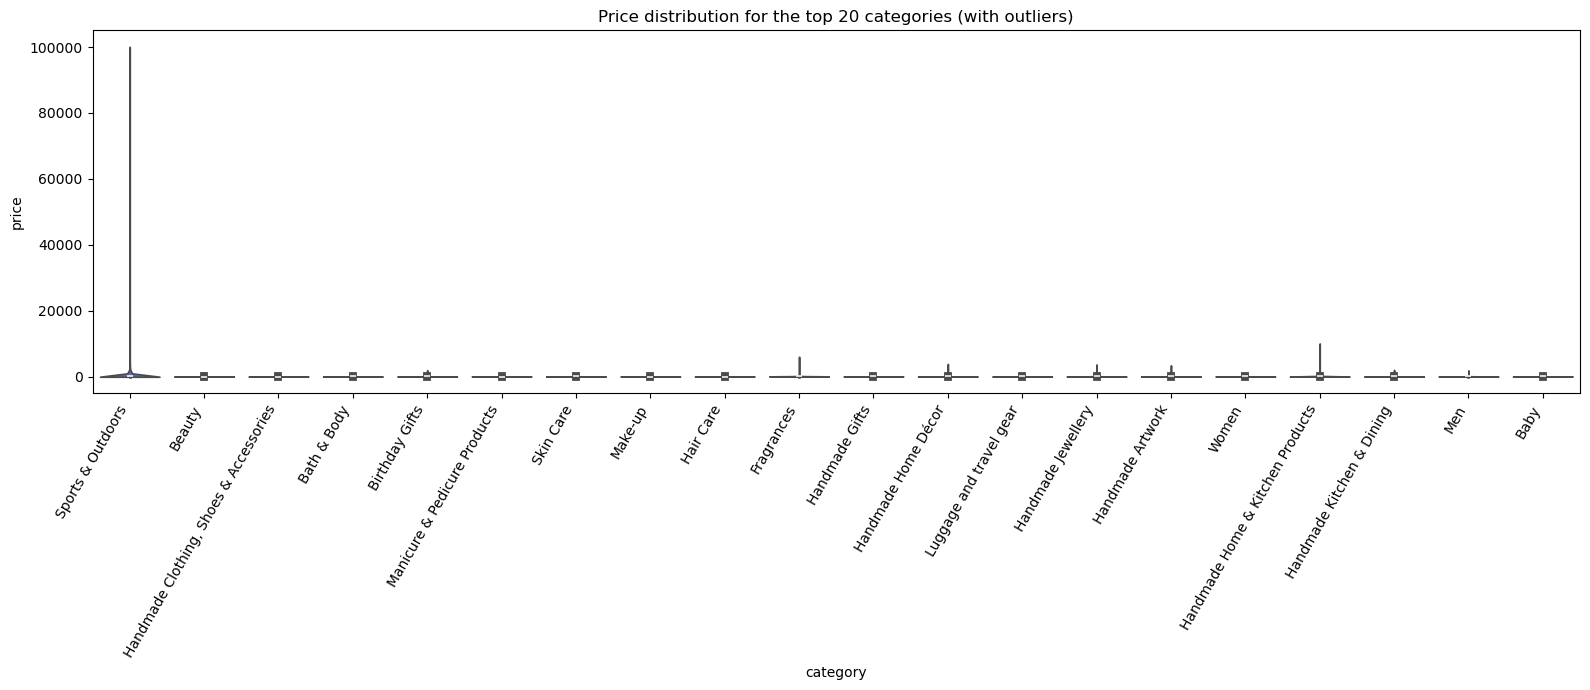

In [34]:
top20_all = df['category'].value_counts().head(20).index

plt.figure(figsize=(16, 7))
sns.violinplot(data=df[df['category'].isin(top20_all)], x='category', y='price', order=top20_all, palette='coolwarm')
plt.title('Price distribution for the top 20 categories (with outliers)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [35]:
pearsonr(df['price'], df['stars']), spearmanr(df['price'], df['stars'])

(PearsonRResult(statistic=np.float64(-0.12490673262148583), pvalue=np.float64(0.0)),
 SignificanceResult(statistic=np.float64(-0.13316425462433998), pvalue=np.float64(0.0)))

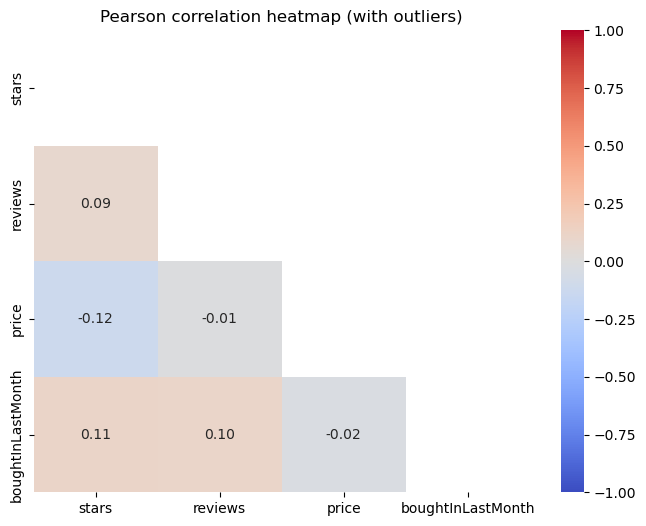

In [36]:
num_all = df.select_dtypes(include='number').drop(columns=['uid'])
mask_all = np.triu(np.ones_like(num_all.corr(), dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(num_all.corr(), mask=mask_all, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation heatmap (with outliers)')
plt.show()

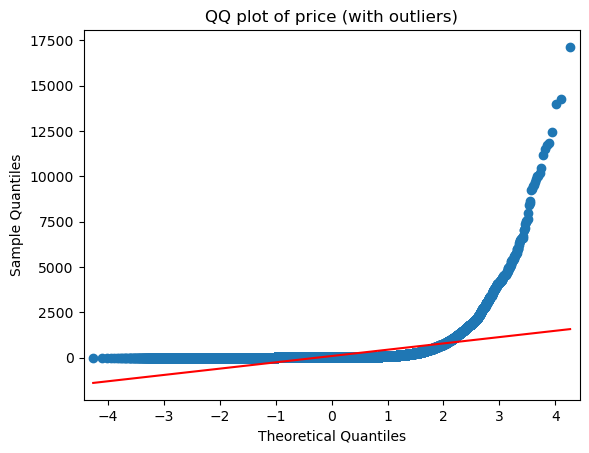

In [37]:
sm.qqplot(df['price'].sample(100_000, random_state=42), line='s')
plt.title('QQ plot of price (with outliers)')
plt.show()

Quite a different picture for prices:
- **Laptops** now lead both the median (~£1,043) and the mean (~£1,088), followed by Desktop PCs, 3D Printers, Snowboards, Record Players and Home Office Furniture. The IQR cut-off at ~£100 had hidden all the genuinely high-ticket categories. These "outliers" are real products, not data errors, so for category-level pricing the removal was too aggressive.
- The violin plots become unreadable: a few extreme prices (up to £100,000) squash every distribution into a flat line at the bottom.
- The price–stars correlation is slightly stronger (Pearson ~-0.12, Spearman ~-0.13) but still very weak.
- Median ratings are basically unchanged (Computer Memory is still at 4.7), so ratings are robust to price outliers.
- The QQ plot is much more extreme (skewness ~27).

---
## 7. Report | Summary of findings

1. **Best-seller status depends on category, but only weakly.**
   Only ~0.33% of products are best-sellers. Grocery, Smart Home Security & Lighting and Health & Personal Care reach ~18x that rate. The Chi-square test confirms the dependence (p ~0), but Cramér's V ~0.12 shows that it's weak.
    > **Business takeaway**: consumable, repeat-purchase categories (Grocery, Health & Personal Care) are where the best-seller badge is most attainable. Elsewhere it's hard to get regardless of the category.

2. **Electronics and computing command the highest prices.**
   Within the typical range (≤ £100), Desktop PCs, Motherboards, Tablets, Graphics Cards and Boxing Shoes have the highest median and mean prices. Including outliers, Laptops, Desktop PCs and 3D Printers dominate. The high-volume categories (Beauty, Bath & Body, Handmade…) are low-ticket.
    > **Business takeaway**: pricing strategies should differ. High-ticket electronics compete on value per unit, high-volume beauty/handmade products compete on volume.

3. **Ratings are high across the board and barely differ by category.**
   Rated products mostly score 4+, with Computer Memory on top (4.7). Half of the catalogue is unrated, which drags many category medians down to 0.
    > **Business takeaway**: getting the first reviews matters more than the category. Unrated products are invisible in any ratings-based comparison.

4. **Price does not drive ratings.**
   The price–stars correlation is very weak (~-0.08) and disappears (~0) among rated products. Cheaper products do sell more units though, and products that sell more collect more reviews.
    > **Business takeaway**: changing the price won't improve ratings; quality and fulfilment will. Price mainly affects sales volume.

5. **Prices are heavily right-skewed and not normal.**
   Medians and Spearman are the better tools here. Removing outliers with the IQR rule (cut at ~£100) helps to look at the typical product but hides entire premium categories.
    > **Business takeaway**: whether to remove outliers depends on the business question being asked.